<a href="https://colab.research.google.com/github/Janani-hari/BMSCE-DATA-VISUALIZATION/blob/main/program1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Dataset Shape: (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2



Continuous Variables:
['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']

Categorical Variables:
[]


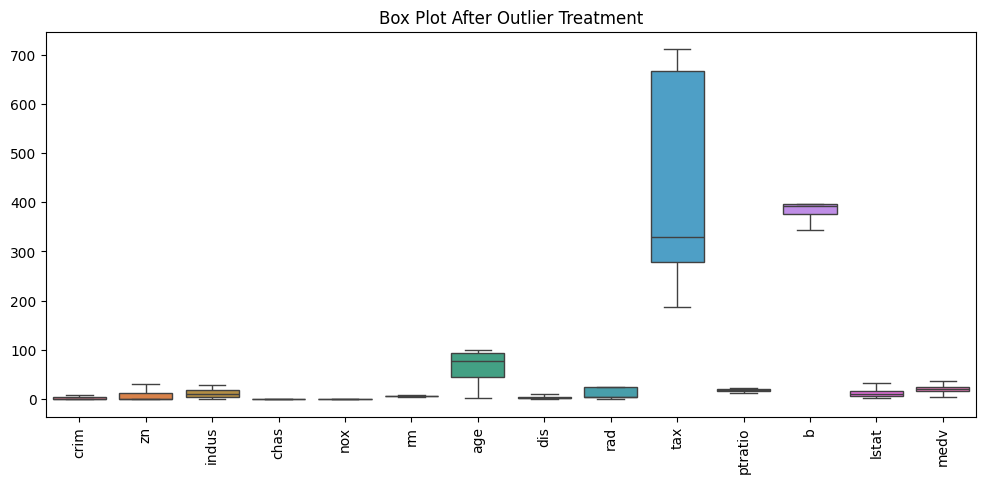

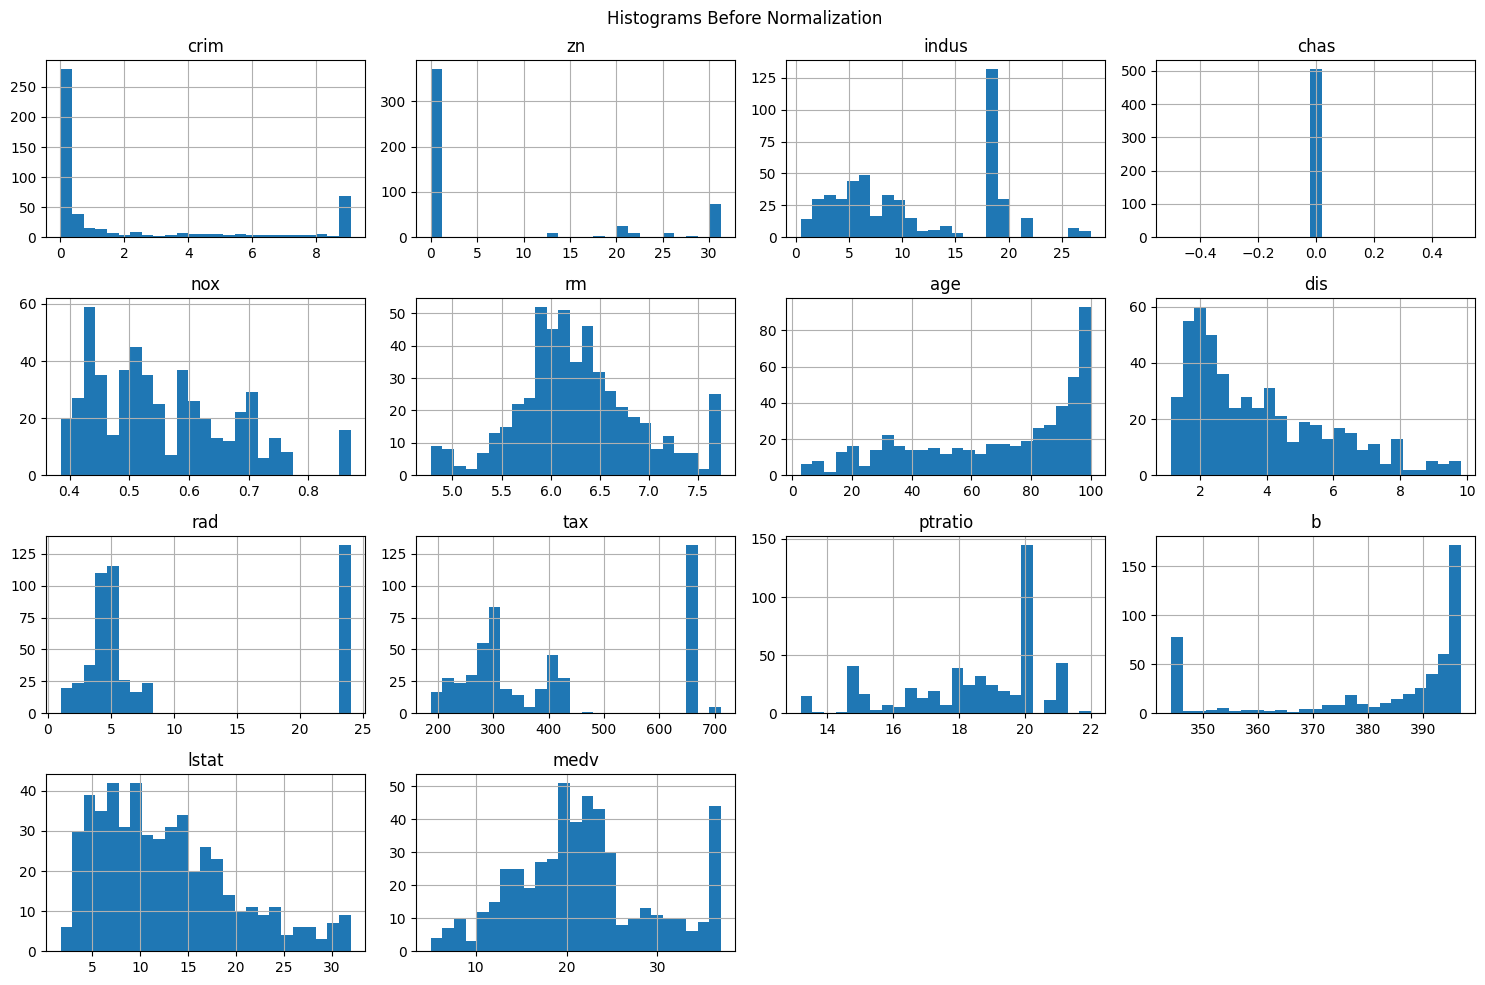

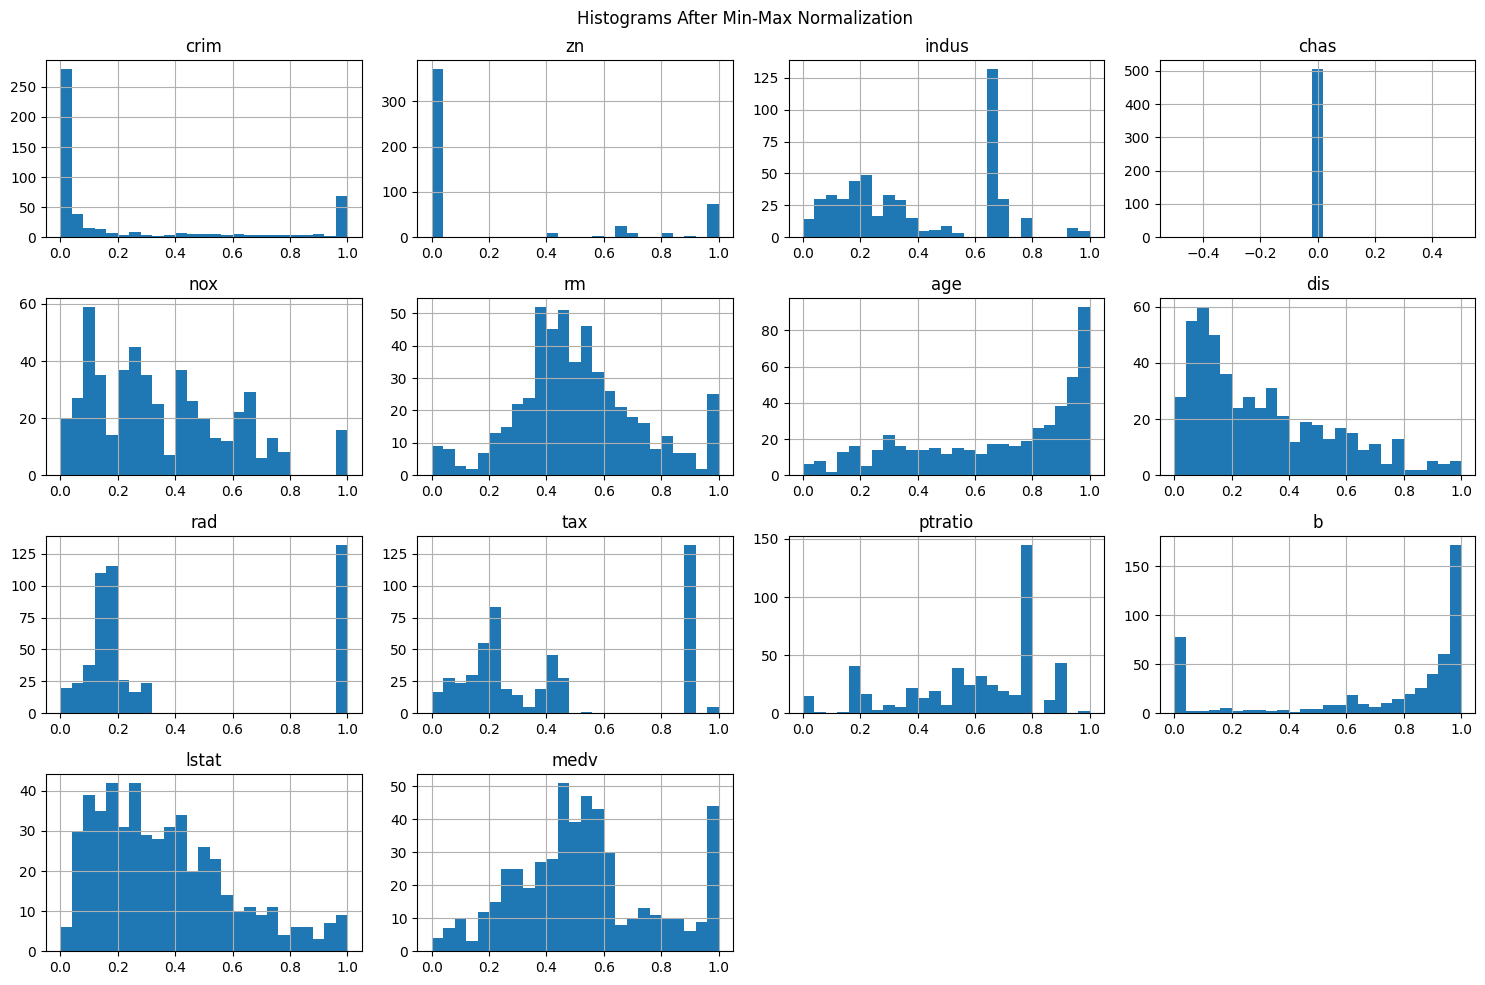

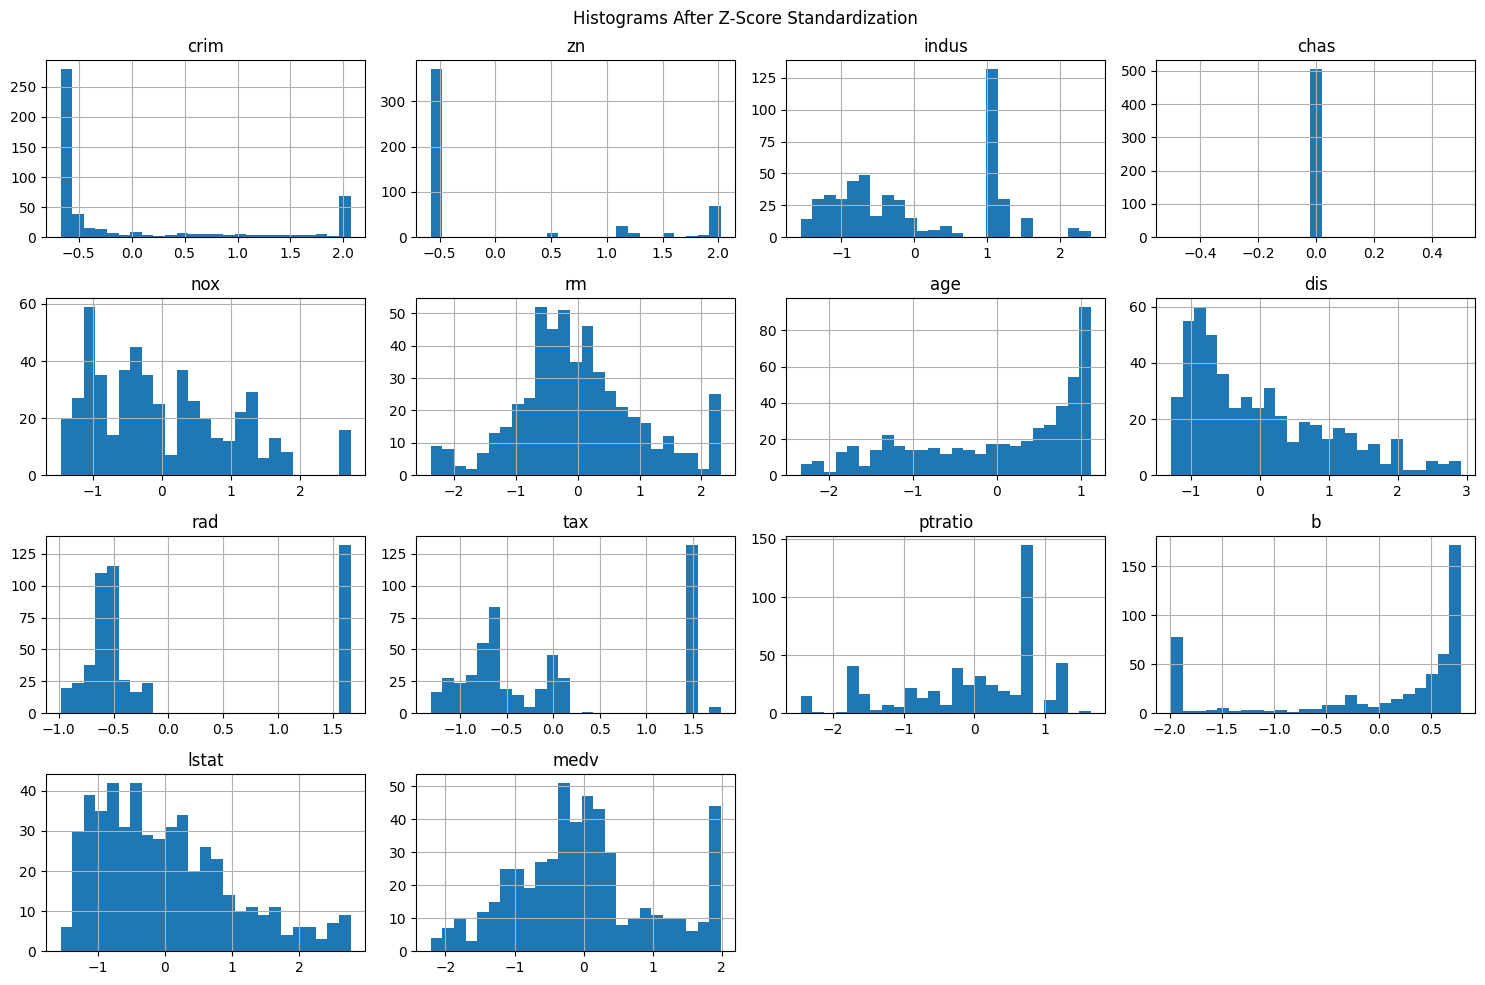

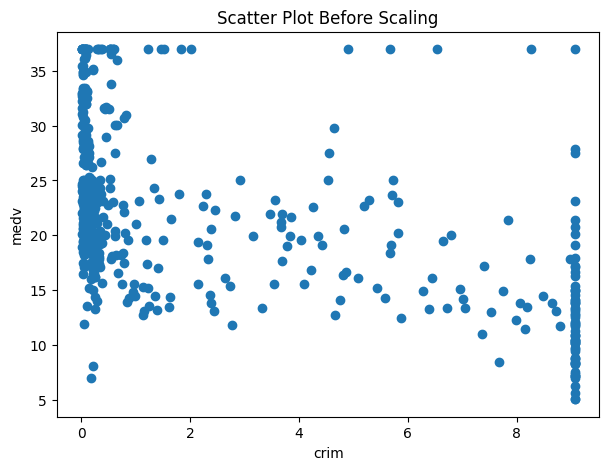

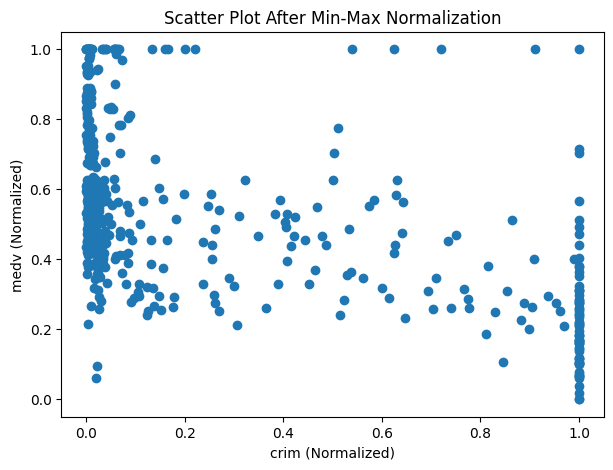

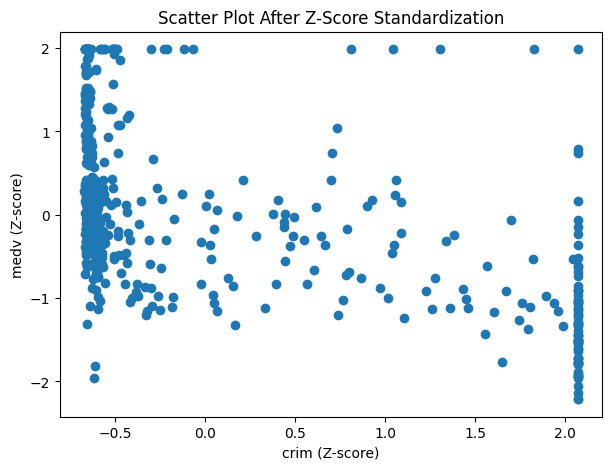


PREPROCESSING COMPLETED SUCCESSFULLY!
Cleaned data      : housing_cleaned.csv
Min-Max data      : housing_minmax.csv
Z-score data      : housing_zscore.csv
Final shape       : (506, 14)
Missing values    : 0
Duplicates        : 0


In [6]:
# ============================================================
# HOUSE PRICE DATASET - COMPLETE PREPROCESSING IN ONE CELL
# ============================================================

!wget -q https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv -O housing.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load dataset
df = pd.read_csv("housing.csv")

print("Original Dataset Shape:", df.shape)
display(df.head())

# ------------------------------------------------------------
# 1. REMOVE DUPLICATES
# ------------------------------------------------------------
df = df.drop_duplicates()

# ------------------------------------------------------------
# 2. HANDLE MISSING VALUES
# ------------------------------------------------------------
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="object").columns

for c in num_cols:
    df[c] = df[c].fillna(df[c].median())

for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

# ------------------------------------------------------------
# 3. OUTLIER TREATMENT USING IQR
# ------------------------------------------------------------
for c in num_cols:
    Q1 = df[c].quantile(0.25)
    Q3 = df[c].quantile(0.75)
    IQR = Q3 - Q1
    df[c] = df[c].clip(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

# ------------------------------------------------------------
# 4. VARIABLE TYPES
# ------------------------------------------------------------
print("\nContinuous Variables:")
print(list(num_cols))

print("\nCategorical Variables:")
print(list(cat_cols))

# ------------------------------------------------------------
# 5. BAR PLOT
# ------------------------------------------------------------
if len(cat_cols) > 0:
    plt.figure(figsize=(10,5))
    df[cat_cols[0]].value_counts().plot(kind="bar")
    plt.title("Bar Plot - Categorical Variable")
    plt.show()

# ------------------------------------------------------------
# 6. BOX PLOT BEFORE/AFTER CLEANING
# ------------------------------------------------------------
plt.figure(figsize=(12,5))
sns.boxplot(data=df[num_cols])
plt.xticks(rotation=90)
plt.title("Box Plot After Outlier Treatment")
plt.show()

# ------------------------------------------------------------
# 7. HISTOGRAM BEFORE SCALING
# ------------------------------------------------------------
df[num_cols].hist(figsize=(15,10), bins=25)
plt.suptitle("Histograms Before Normalization")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. MIN-MAX NORMALIZATION
# ------------------------------------------------------------
minmax = MinMaxScaler()
df_minmax = df.copy()
df_minmax[num_cols] = minmax.fit_transform(df[num_cols])

# ------------------------------------------------------------
# 9. Z-SCORE STANDARDIZATION
# ------------------------------------------------------------
zscore = StandardScaler()
df_zscore = df.copy()
df_zscore[num_cols] = zscore.fit_transform(df[num_cols])

# ------------------------------------------------------------
# 10. HISTOGRAM AFTER MIN-MAX
# ------------------------------------------------------------
df_minmax[num_cols].hist(figsize=(15,10), bins=25)
plt.suptitle("Histograms After Min-Max Normalization")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. HISTOGRAM AFTER Z-SCORE
# ------------------------------------------------------------
df_zscore[num_cols].hist(figsize=(15,10), bins=25)
plt.suptitle("Histograms After Z-Score Standardization")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. SCATTER PLOT
# ------------------------------------------------------------
x = num_cols[0]
y = num_cols[-1]

plt.figure(figsize=(7,5))
plt.scatter(df[x], df[y])
plt.xlabel(x)
plt.ylabel(y)
plt.title("Scatter Plot Before Scaling")
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(df_minmax[x], df_minmax[y])
plt.xlabel(x + " (Normalized)")
plt.ylabel(y + " (Normalized)")
plt.title("Scatter Plot After Min-Max Normalization")
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(df_zscore[x], df_zscore[y])
plt.xlabel(x + " (Z-score)")
plt.ylabel(y + " (Z-score)")
plt.title("Scatter Plot After Z-Score Standardization")
plt.show()

# ------------------------------------------------------------
# 13. SAVE RESULTS
# ------------------------------------------------------------
df.to_csv("housing_cleaned.csv", index=False)
df_minmax.to_csv("housing_minmax.csv", index=False)
df_zscore.to_csv("housing_zscore.csv", index=False)

print("\n==========================================")
print("PREPROCESSING COMPLETED SUCCESSFULLY!")
print("==========================================")
print("Cleaned data      : housing_cleaned.csv")
print("Min-Max data      : housing_minmax.csv")
print("Z-score data      : housing_zscore.csv")
print("Final shape       :", df.shape)
print("Missing values    :", df.isnull().sum().sum())
print("Duplicates        :", df.duplicated().sum())